Understand how individual item prices evolve over time during a league and identify patterns such as volatility, stability, and early-league price spikes.

## Importing libraries

In [150]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from itables import show
import plotly.graph_objects as go
import numpy as np
import seaborn as sns

## Importing data

In [151]:
items_processed = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_processed/high_conf_items_processed_day.csv", sep=";", low_memory=False)

# Item Price Dynamics 

## Daily price changes of an item during a league

In [152]:
item_time_series = (items_processed.groupby(["League", "Name", "Day"])["Value"].median().reset_index())
show(item_time_series)


Loading ITables v2.7.0 from the internet... (need help?)


## Average price of each item across the leagues

In [206]:
mean_price_per_item = (item_time_series.groupby(["League", "Name"])["Value"].mean().reset_index(name="mean_price"))
mean_price_per_item

,League,Name,mean_price
0,Affliction,+1% Chance to Block Attack Damage,3.473624
1,Affliction,+12% to Chaos Resistance,8.633091
2,Affliction,+15% to Cold Resistance,2.574045
3,Affliction,+15% to Fire Resistance,3.526136
4,Affliction,+15% to Lightning Resistance,2.776386
...,...,...,...
28635,Settlers,Zeel's Amplifier,1.000000
28636,Settlers,Zerphi's Heart,552.076894
28637,Settlers,Zerphi's Last Breath,7.358994
28638,Settlers,Ziggurat Map,86.819748


In [207]:
mean_price_per_item.sort_values("mean_price",ascending=False).head(10)

,League,Name,mean_price
18434,Mercenaries,Original Sin,209103.954812
16353,Mercenaries,Awakened Enlighten Support,207124.053011
2209,Affliction,Original Sin,191305.444794
26803,Settlers,Original Sin,174735.985382
20645,Necropolis,Awakened Enlighten Support,139515.313600
16351,Mercenaries,Awakened Empower Support,137582.176163
3333,Affliction,The Original Scripture,136725.432337
19679,Mercenaries,The Original Scripture,132508.652836
22656,Necropolis,Original Sin,112443.537035
13690,Keepers,Original Sin,99322.158347


## Items segmentation

Because of the specific character of the PoE market which is highly skewed the segmentation was done using percentile thresholds. This approach allows the expensive segment to represent only a small proportion of items, corresponding more closely to the observed long-tail distribution of item prices in Path of Exile.

In [155]:
q80 = mean_price_per_item["mean_price"].quantile(0.8)
q95 = mean_price_per_item["mean_price"].quantile(0.95)

def segment(p):
    if p <= q80:
        return "cheap"
    elif p <= q95:
        return "mid-range"
    else:
        return "expensive"

mean_price_per_item["price_segment"] = mean_price_per_item["mean_price"].apply(segment)
mean_price_per_item["price_segment"].value_counts(normalize=True) * 100

price_segment
cheap        80.0
mid-range    15.0
expensive     5.0
Name: proportion, dtype: float64

In [156]:
mean_price_per_item.sort_values("mean_price").head(10)

,League,Name,mean_price,price_segment
12150,Keepers,Fencoil,0.080697,cheap
5908,Ancestor,Clear Oil,0.090917,cheap
8783,Ancestor,Sepia Oil,0.092431,cheap
21194,Necropolis,Clear Oil,0.093103,cheap
23170,Necropolis,Sepia Oil,0.102845,cheap
12941,Keepers,Hrimnor's Hymn,0.105000,cheap
2747,Affliction,Sepia Oil,0.106743,cheap
792,Affliction,Clear Oil,0.107615,cheap
20483,Necropolis,Amber Oil,0.121681,cheap
14278,Keepers,Saemus' Gift,0.121748,cheap


In [157]:
mean_price_per_item.sort_values("mean_price").tail(10)

,League,Name,mean_price,price_segment
13690,Keepers,Original Sin,99322.158347,expensive
22656,Necropolis,Original Sin,112443.537035,expensive
19679,Mercenaries,The Original Scripture,132508.652836,expensive
3333,Affliction,The Original Scripture,136725.432337,expensive
16351,Mercenaries,Awakened Empower Support,137582.176163,expensive
20645,Necropolis,Awakened Enlighten Support,139515.313600,expensive
26803,Settlers,Original Sin,174735.985382,expensive
2209,Affliction,Original Sin,191305.444794,expensive
16353,Mercenaries,Awakened Enlighten Support,207124.053011,expensive
18434,Mercenaries,Original Sin,209103.954812,expensive


## Price evolution over time

For the better analysis and visualisation the set of representative itmes were selcted. The representative basket was chosen based on the knowledge of the game - these are the very popular items in each league from differnt types. Mostly unique items were chosen because of the complexity of the non-unique items in the game. The analysis mainly focused on items that can be equipped by the character, as this largely determines their popularity in the game.

The basket contains: chase items (Mageblood, Headhunter, Nimis), meta build items (Heatshiver, Covenant), stable items (Aegis Aurora, Rumi's).

In [158]:
#Items selection
selected_basket = {
    "Aegis Aurora": "UniqueArmour",
    "Amanamu's Gaze": "UniqueJewel",
    "Anathema": "UniqueAccessory",
    "Ashes of the Stars": "UniqueAccessory",
    "Aul's Uprising": "UniqueAccessory",
    "Awakened Multistrike Support": "SkillGem",
    "Darkness Enthroned": "UniqueAccessory",
    "Dying Sun": "UniqueFlask",
    "Heatshiver": "UniqueArmour",
    "Headhunter": "UniqueAccessory",
    "Inspired Learning": "UniqueJewel",
    "Kingmaker": "UniqueWeapon",
    "Kitava's Thirst": "UniqueArmour",
    "Mageblood": "UniqueAccessory",
    "Nimis": "UniqueAccessory",
    "Progenesis": "UniqueFlask",
    "Ralakesh's Impatience": "UniqueArmour",
    "Replica Alberon's Warpath": "UniqueArmour",
    "Rumi's Concoction": "UniqueFlask",
    "Ryslatha's Coil": "UniqueAccessory",
    "Seven-League Step": "UniqueArmour",
    "Starforge": "UniqueWeapon",
    "Svalinn": "UniqueArmour",
    "The Covenant": "UniqueArmour",
    "The Jinxed Juju": "UniqueAccessory",
    "The Squire": "UniqueArmour",
    "The Surrender": "UniqueArmour",
    "The Taming": "UniqueAccessory",
    "Unnatural Instinct": "UniqueJewel",
    "Void Battery": "UniqueWeapon"
}

In [159]:
#anlysing whether the chosen basket is representative of the segments distribution
basket= pd.DataFrame(list(selected_basket.items()),columns=["Name", "Type"])
basket.reset_index(drop=True).to_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_processed/basket.csv",sep=";",index=False)

segments_unique = mean_price_per_item[["Name", "price_segment"]].drop_duplicates("Name")
basket_segments = basket.merge(segments_unique,on="Name",how="left")
basket_segments

,Name,Type,price_segment
0,Aegis Aurora,UniqueArmour,mid-range
1,Amanamu's Gaze,UniqueJewel,expensive
2,Anathema,UniqueAccessory,mid-range
3,Ashes of the Stars,UniqueAccessory,expensive
4,Aul's Uprising,UniqueAccessory,mid-range
5,Awakened Multistrike Support,SkillGem,expensive
6,Darkness Enthroned,UniqueAccessory,cheap
7,Dying Sun,UniqueFlask,mid-range
8,Heatshiver,UniqueArmour,cheap
9,Headhunter,UniqueAccessory,expensive


In [160]:
items_each_segment = basket_segments.groupby("price_segment")["Name"].count()
ratio_segments = items_each_segment /items_each_segment.sum() * 100
items_each_segment, ratio_segments


(price_segment
 cheap         9
 expensive    13
 mid-range     8
 Name: Name, dtype: int64,
 price_segment
 cheap        30.000000
 expensive    43.333333
 mid-range    26.666667
 Name: Name, dtype: float64)

The basket contains sufficient number of items in each segment. There are more expensive items as they are usually the most desired by the players, but the number of items in this segment is not significantly larger than the others (43%).

In [161]:
selected_items = list(selected_basket.keys())

selected_data = item_time_series[item_time_series["Name"].isin(selected_items)]

leagues = item_time_series["League"].unique()


Having all the data on a single plot is not very informative due to the large number of items and the differences in their price scales.

For a clearer analysis and visualisation, items could be grouped by price segment.

In [162]:
cheap_items = basket_segments[basket_segments["price_segment"] == "cheap"]["Name"].tolist()
mid_items = basket_segments[basket_segments["price_segment"] == "mid-range"]["Name"].tolist()
expensive_items = basket_segments[basket_segments["price_segment"] == "expensive"]["Name"].tolist()

#### Price evolution of itmes within each segment by leagues

In [163]:
def plot_segment(selected_data, items):

    leagues = selected_data["League"].unique()

    fig = go.Figure()

    # dodanie wszystkich serii
    for league in leagues:
        for item in items:

            data = selected_data[(selected_data["League"] == league) & (selected_data["Name"] == item)]

            fig.add_trace(
                go.Scatter(
                    x=data["Day"],
                    y=data["Value"],
                    mode="lines",
                    name=f"{item} ({league})",
                    visible=(league == leagues[0])
                )
            )

    # liczba itemów w segmencie
    n_items = len(items)

    # dropdown dla lig
    buttons = []
    for i, league in enumerate(leagues):

        visible = [False] * len(fig.data)

        start = i * n_items
        end = start + n_items

        for j in range(start, end):
            visible[j] = True

        buttons.append(
            dict(
                label=league,
                method="update",
                args=[{"visible": visible}]
            )
        )

    fig.update_layout(
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                showactive=True
            )
        ],
        title="Price evolution by league",
        xaxis_title="League day",
        yaxis_title="Chaos price"
    )

    fig.show()

In [164]:
# price evolution for expensive segment 
plot_segment(selected_data, expensive_items)

In [165]:
#price evolution for mid-range segment
plot_segment(selected_data, mid_items)

In [166]:
#price evolution for cheap segment
plot_segment(selected_data, cheap_items)

#### Price evolution of one representative item within each segment

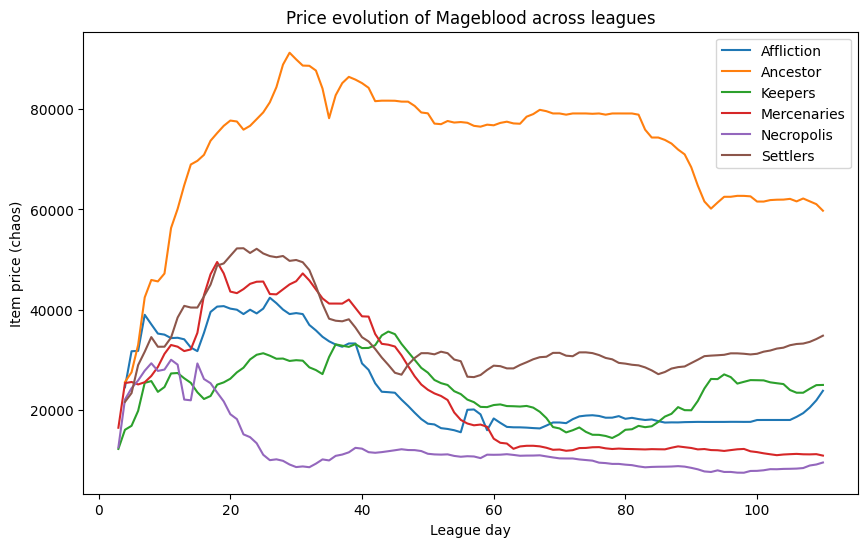

In [167]:
# price evolution plot for one representative item - expensive segment
item_expensive="Mageblood"
max_day = 110 # focus on the first 110 days - the lenght of two shortest leagues
item_data = item_time_series[(item_time_series["Name"] ==item_expensive) &(item_time_series["Day"] <= max_day)]

plt.figure(figsize=(10,6))

for league in item_data["League"].unique():
    
    data = item_data[item_data["League"] == league]
    plt.plot(data["Day"],data["Value"],label=league)

plt.xlabel("League day")
plt.ylabel("Item price (chaos)")
plt.title(f"Price evolution of {item_expensive} across leagues")

plt.legend()
plt.show()


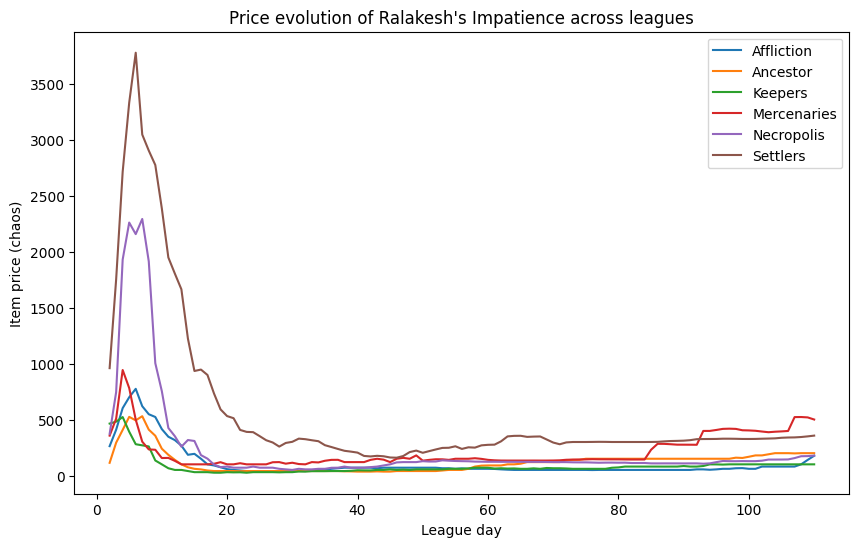

In [168]:
# price evolution plot for one representative item - medium-range segment
item_medium="Ralakesh's Impatience"
max_day = 110 # focus on the first 110 days - the lenght of two shortest leagues
item_data = item_time_series[(item_time_series["Name"] ==item_medium) &(item_time_series["Day"] <= max_day)]

plt.figure(figsize=(10,6))

for league in item_data["League"].unique():
    
    data = item_data[item_data["League"] == league]
    plt.plot(data["Day"],data["Value"],label=league)

plt.xlabel("League day")
plt.ylabel("Item price (chaos)")
plt.title(f"Price evolution of {item_medium} across leagues")

plt.legend()
plt.show()

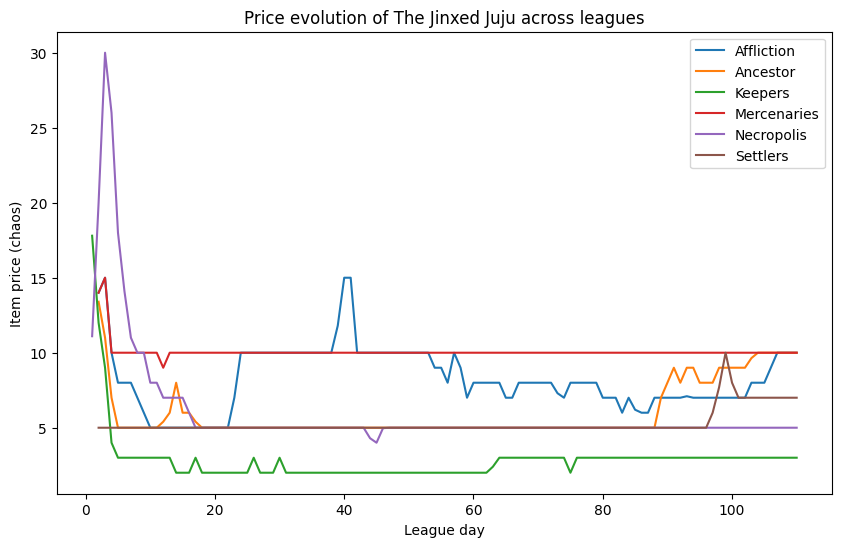

In [169]:
# price evolution plot for one representative item - medium-range segment
item_cheap="The Jinxed Juju"
max_day = 110 # focus on the first 110 days - the lenght of two shortest leagues
item_data = item_time_series[(item_time_series["Name"] ==item_cheap) &(item_time_series["Day"] <= max_day)]

plt.figure(figsize=(10,6))

for league in item_data["League"].unique():
    
    data = item_data[item_data["League"] == league]
    plt.plot(data["Day"],data["Value"],label=league)

plt.xlabel("League day")
plt.ylabel("Item price (chaos)")
plt.title(f"Price evolution of {item_cheap} across leagues")

plt.legend()
plt.show()

## Daily price change

In [170]:
item_time_series = item_time_series.sort_values(["League", "Name", "Day"])
item_time_series["daily_change"] = item_time_series.groupby(["League", "Name"])["Value"].pct_change()


item_time_series = item_time_series.merge(mean_price_per_item[["League", "Name", "price_segment"]],on=["League", "Name"],how="left")
item_time_series

,League,Name,Day,Value,daily_change,price_segment
0,Affliction,+1% Chance to Block Attack Damage,2,1.0,NaN,cheap
1,Affliction,+1% Chance to Block Attack Damage,3,1.0,0.000000,cheap
2,Affliction,+1% Chance to Block Attack Damage,4,1.0,0.000000,cheap
3,Affliction,+1% Chance to Block Attack Damage,5,1.0,0.000000,cheap
4,Affliction,+1% Chance to Block Attack Damage,6,1.0,0.000000,cheap
...,...,...,...,...,...,...
3871051,Settlers,Zodiac Leather,315,15.0,0.200000,cheap
3871052,Settlers,Zodiac Leather,316,11.2,-0.253333,cheap
3871053,Settlers,Zodiac Leather,317,10.0,-0.107143,cheap
3871054,Settlers,Zodiac Leather,318,10.0,0.000000,cheap


## Price volatility

In [171]:
volatility = item_time_series.groupby(["League", "Name"])["daily_change"].std().reset_index(name="volatility")

# removing items with insufficient data (std can't be calculated) - first day of each league
volatility = volatility.dropna(subset=["volatility"])

In [172]:
volatility.groupby(["Name","League"])["volatility"].first()

Name                                 League     
+0.5 metres to Discharge radius      Ancestor       0.161130
+1 to Maximum Blood Charges          Ancestor       0.139624
+1 to maximum Blade Flurry stages    Ancestor       0.115587
+1 to maximum Snipe Stages           Ancestor       0.213777
+1 to maximum number of Bladestorms  Ancestor       0.127853
                                                      ...   
Zodiac Leather                       Ancestor       0.094463
                                     Keepers        0.226884
                                     Mercenaries    0.090616
                                     Necropolis     0.128024
                                     Settlers       0.139603
Name: volatility, Length: 28555, dtype: float64

In [173]:
volatility[volatility["Name"] == "Aegis Aurora"]

,League,Name,volatility
78,Affliction,Aegis Aurora,0.106654
4625,Ancestor,Aegis Aurora,0.126755
10289,Keepers,Aegis Aurora,0.108447
16143,Mercenaries,Aegis Aurora,0.103191
20382,Necropolis,Aegis Aurora,0.078639
24499,Settlers,Aegis Aurora,0.081313


#### Most volatile items in a specific league 

In [174]:
volatility.sort_values("volatility", ascending=False).head(20)

,League,Name,volatility
20583,Necropolis,Asphyxia's Wrath,1850.120897
15688,Keepers,Vaal Ground Slam,1244.679399
24639,Settlers,Asphyxia's Wrath,1232.023330
14233,Keepers,Runegraft of the Angler,897.687831
15663,Keepers,Vaal Blight,777.777851
26067,Settlers,Goatman Fire-raiser,720.423836
20908,Necropolis,Blighted Iceberg Map,620.147140
12259,Keepers,Forbidden Power,520.884583
5268,Ancestor,Asphyxia's Wrath,224.237599
27207,Settlers,Ruins Hellion,127.034524


#### Most stable items in a specific league

In [175]:
volatility.sort_values("volatility", ascending=False).tail(20)

,League,Name,volatility
10022,Ancestor,Wailing Essence of Suffering,0.0
14220,Keepers,Ruinous Wager,0.0
10023,Ancestor,Wailing Essence of Torment,0.0
16999,Mercenaries,Coralito's Signature,0.0
1553,Affliction,Gorgon's Gaze,0.0
23202,Necropolis,Shavronne's Pace,0.0
2587,Affliction,Rive,0.0
1570,Affliction,Great Old One's Tentacles,0.0
1571,Affliction,Great Old One's Ward,0.0
21143,Necropolis,Chain of Endurance,0.0


#### Price segment volatility

Due to large differences in price levels between items, a logarithmic scale was applied to the price values.

In [176]:
item_time_series["log_return"] = (np.log(item_time_series["Value"] /item_time_series.groupby(["League","Name"])["Value"].shift(1)))

segment_volatility = (item_time_series.groupby("price_segment")["log_return"].std())
segment_volatility

price_segment
cheap        0.202790
expensive    0.238747
mid-range    0.278367
Name: log_return, dtype: float64

In [177]:
segment_volatility_league = (item_time_series.groupby(["League","price_segment"])["log_return"].std().unstack())
segment_volatility_league

price_segment,cheap,expensive,mid-range
League,,,
Affliction,0.162975,0.225925,0.228808
Ancestor,0.174343,0.220775,0.257144
Keepers,0.299124,0.326163,0.387612
Mercenaries,0.175531,0.206938,0.278702
Necropolis,0.164869,0.245073,0.260597
Settlers,0.197420,0.212745,0.253739


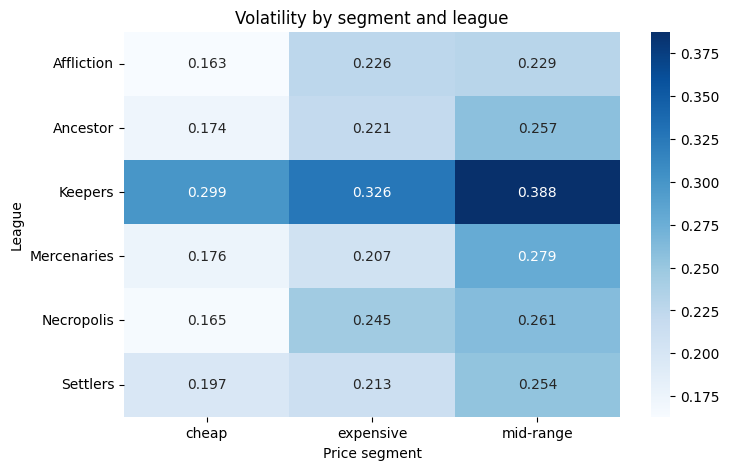

In [178]:
plt.figure(figsize=(8, 5))
sns.heatmap(segment_volatility_league, annot=True, cmap="Blues", fmt=".3f")
plt.title("Volatility by segment and league")
plt.xlabel("Price segment")
plt.ylabel("League")
plt.show()

## Early league price spikes

In [185]:
price_day1 = (item_time_series.sort_values("Day").groupby(["League","Name"]).first().reset_index())
price_day5 = (item_time_series[item_time_series["Day"] <= 5].sort_values("Day").groupby(["League","Name"]).last().reset_index())

In [187]:
price_spikes = price_day1.merge(price_day5,on=["League","Name"],suffixes=("_day1","_day5"))
price_spikes

,League,Name,Day_day1,Value_day1,daily_change_day1,price_segment_day1,log_return_day1,Day_day5,Value_day5,daily_change_day5,price_segment_day5,log_return_day5
0,Affliction,+1% Chance to Block Attack Damage,2,1.00,0.000000,cheap,0.000000,5,1.0,0.000000,cheap,0.000000
1,Affliction,+12% to Chaos Resistance,1,1.00,0.000000,cheap,0.000000,5,1.0,0.000000,cheap,0.000000
2,Affliction,+15% to Cold Resistance,1,1.00,0.000000,cheap,0.000000,5,1.0,0.000000,cheap,0.000000
3,Affliction,+15% to Fire Resistance,1,1.00,0.000000,cheap,0.000000,5,1.0,0.000000,cheap,0.000000
4,Affliction,+15% to Lightning Resistance,1,1.00,0.000000,cheap,0.000000,5,1.0,0.000000,cheap,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
25409,Settlers,Zeel's Amplifier,2,1.00,0.000000,cheap,0.000000,5,1.0,0.000000,cheap,0.000000
25410,Settlers,Zerphi's Heart,3,4.30,1.302326,expensive,0.833920,4,9.9,1.302326,expensive,0.833920
25411,Settlers,Zerphi's Last Breath,2,3.00,-0.666667,cheap,-1.098612,5,1.0,0.000000,cheap,0.000000
25412,Settlers,Ziggurat Map,2,15.00,0.133333,mid-range,0.125163,5,35.0,0.000000,mid-range,0.000000


In [ ]:
price_spikes["price_spike"] = price_spikes["Value_day5"] / price_spikes["Value_day1"]
price_spikes.sort_values("price_spike",ascending=False)[["League","Name","price_spike","Value_day1","Value_day5"]].head(20)

,League,Name,price_spike,Value_day1,Value_day5
21201,Necropolis,Vaal Lightning Strike,244.151515,0.33,80.5700
21200,Necropolis,Vaal Lightning Arrow,229.136364,0.33,75.6150
21166,Necropolis,Vaal Blade Vortex,210.606061,0.33,69.5000
21161,Necropolis,Vaal Arc,189.393939,0.33,62.5000
25164,Settlers,Vaal Lightning Strike,160.160000,1.00,160.1600
21172,Necropolis,Vaal Caustic Arrow,147.727273,0.33,48.7500
21178,Necropolis,Vaal Detonate Dead,127.670000,1.00,127.6700
21216,Necropolis,Vaal Smite,115.757576,0.33,38.2000
21213,Necropolis,Vaal Rejuvenation Totem,111.515152,0.33,36.8000
14253,Mercenaries,Ceaseless Feast,108.725000,2.00,217.4500


In [201]:
#Highest 20 price spikes per league.
top_spikes_per_league = (price_spikes.sort_values(["League", "price_spike"], ascending=[True, False]).groupby("League").head(20))
top_spikes_per_league[["League","Name","price_spike","Value_day1","Value_day5"]]
top_spikes_per_league.groupby(["League", "Name"])["price_spike"].first()

League      Name                          
Affliction  Animate Guardian                   30.450000
            Arrogance Support                  24.150000
            Bone Helmet                        45.994167
            Cast when Damage Taken Support     30.000000
            Concentrated Effect Support        30.000000
                                                 ...    
Settlers    Storm Brand of Indecision          81.750000
            Swift Assembly Support             31.600000
            Tempest Shield                     39.545455
            Vaal Lightning Strike             160.160000
            Volatility Support                 62.500000
Name: price_spike, Length: 120, dtype: float64

In [ ]:
# Items that may be good investments at the early stage of the league
item_frequency = top_spikes_per_league["Name"].value_counts()
item_frequency.head(10)

Name
Volatility Support                   4
Cyclone of Tumult                    3
Void Manipulation Support            3
Vaal Smite                           3
Arrogance Support                    3
Vaal Caustic Arrow                   2
Increased Critical Damage Support    2
Rain of Arrows of Saturation         2
Storm Brand of Indecision            2
Tempest Shield                       2
Name: count, dtype: int64

In [203]:
price_day8 = item_time_series[item_time_series["Day"] == 8]
price_day15 =item_time_series[item_time_series["Day"] == 15]

price_spikes2 = price_day8.merge(price_day15,on=["League","Name"],suffixes=("_day8","_day15"))
price_spikes2["price_spike"] = price_spikes2["Value_day15"] / price_spikes2["Value_day8"]


In [204]:
top_spikes_per_league_2week = (price_spikes2.sort_values(["League", "price_spike"], ascending=[True, False]).groupby("League").head(20))
top_spikes_per_league_2week[["League","Name","price_spike","Value_day8","Value_day15"]]
top_spikes_per_league_2week.groupby(["League", "Name"])["price_spike"].first()

League      Name                                   
Affliction  Awakened Ancestral Call Support            11.282741
            Awakened Cast While Channelling Support     6.480200
            Awakened Enhance Support                    6.434598
            Block Chance Reduction Support             26.149425
            Creeping Frost                              8.750000
                                                         ...    
Settlers    Summon Ice Golem of Shattering             15.238095
            Usurper's Penance                           8.000000
            Vaal Molten Shell                           9.830000
            Voidfletcher                                9.952500
            Voidwalker                                 13.000000
Name: price_spike, Length: 120, dtype: float64

In [205]:
item_frequency2 = top_spikes_per_league_2week["Name"].value_counts()
item_frequency2.head(10)

Name
Inextricable Fate                          4
Dawnstrider                                4
Solstice Vigil                             4
The Gluttonous Tide                        2
Emperor's Cunning                          2
Double Strike of Impaling                  2
Awakened Controlled Destruction Support    2
Faithguard                                 2
Vaal Lightning Strike                      2
Block Chance Reduction Support             2
Name: count, dtype: int64

**Coclusions:** 

The analysis of item price dynamics reveals several consistent patterns in the Path of Exile economy:

1. Some of items consistently have extreme high prices across multiple leagues. 

2. The analysis of price evolution across leagues shows that price dynamics differ between market price segments. **High-value items** exhibit large price differences between leagues and relatively strong fluctuations during the league. Prices are typically high from the beginning and often decrease gradually over time. Items from the **mid-range** segment tend to experience very strong price movements at the beginning of the league. In several leagues the price rises sharply during the first days and then declines quickly as the item becomes more widely available. **Low-priced items** show much more stable behaviour. After a short adjustment period at the beginning of the league their prices usually remain relatively constant and change only slightly during the rest of the league.

3. The calculated **volatility** measures show that some items experience large day-to-day price fluctuations, while others remain relatively stable throughout the league. Also, the volatility analysis shows that price fluctuations differ across both leagues and price segments. In most leagues, mid-range and expensive items tend to exhibit higher volatility than cheap items, indicating stronger day-to-day price changes. At the same time, the overall level of volatility is relatively similar across most leagues. One league, however,the **Keepers League**, shows significantly higher volatility across all price segments, reaching levels of approximately 30–40%.
This can likely be explained by several factors specific to this league. In the Keepers League, asynchronous trading was introduced, allowing players to buy and sell non-currency items without directly meeting in a shared instance. This change may have increased market activity and liquidity. Additionally, new unique items were introduced, which led to the emergence of new meta builds. As players gradually discovered new item combinations, this likely contributed to increased fluctuations in item prices.

4. The **early-league spike** analysis confirms that some items experience very large price increases during the first few days of a league. This is likely caused by limited supply at the beginning of the league combined with high demand.

5. By identifying items that repeatedly appear among the largest early-league spikes across multiple leagues, it is possible to detect items that consistently gain value at the start of a league. These items may represent potential early-league investment opportunities, as their prices tend to increase rapidly in the initial phase of the league.